# Módulo 24: Máquinas de soporte vectorial

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio [instrucciones.md](instrucciones.md). No es una tarea entregada del programa.

Las **máquinas de soporte vectorial** (SVM, por sus siglas en inglés) buscan la frontera que separa dos clases con el mayor margen posible. Gracias al **truco del kernel**, la misma idea sirve para fronteras curvas sin calcular nuevas variables de forma explícita. En esta lección se arma un flujo completo de clasificación binaria, desde la codificación de variables hasta la predicción de un registro nuevo:

1. Datos y desbalance de clases
2. Variables categóricas con `get_dummies`
3. División estratificada
4. Por qué escalar antes de una SVM
5. Margen máximo y vectores de soporte
6. Margen suave y el parámetro C
7. El truco del kernel
8. Matriz de confusión y métricas
9. Elegir la métrica adecuada
10. Predecir un registro nuevo
11. Errores frecuentes
12. Ejercicio

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score, accuracy_score)

## 1. Datos y desbalance de clases

Se usa el archivo `data/recursos-humanos.csv`, con 14.999 empleados y la columna `left` (1 = dejó la empresa). Entrenar una SVM con kernel cuesta entre $O(n^2)$ y $O(n^3)$ operaciones, así que para que la lección corra en pocos segundos se toma una **submuestra estratificada de 2.000 filas**: conserva la misma proporción de cada clase que el archivo completo.

Que una clase sea minoritaria (**desbalance**) importa: un modelo que siempre predice "se queda" acertaría en la mayoría de los casos sin aprender nada.

In [2]:
rh_completo = pd.read_csv("data/recursos-humanos.csv")
print("Archivo completo:", rh_completo.shape)

# train_test_split con stratify sirve también para submuestrear manteniendo proporciones
rh, _ = train_test_split(rh_completo, train_size=2000,
                         stratify=rh_completo["left"], random_state=42)
print("Submuestra:", rh.shape)
print(pd.DataFrame({
    "completo": rh_completo["left"].value_counts(normalize=True).round(3),
    "submuestra": rh["left"].value_counts(normalize=True).round(3),
}))

Archivo completo: (14999, 10)
Submuestra: (2000, 10)
      completo  submuestra
left                      
0        0.762       0.762
1        0.238       0.238


## 2. Variables categóricas con `get_dummies`

Una SVM solo entiende números. Las columnas de texto se codifican según su tipo:

| Tipo | Ejemplo | Codificación |
| --- | --- | --- |
| Nominal (sin orden) | `sales`: departamento | Una columna 0/1 por categoría (`pd.get_dummies`) |
| Ordinal (con orden) | `salary`: low < medium < high | Un entero que respete el orden, o también dummies |

Con `drop_first=True` se elimina la primera categoría, que queda como referencia: si todas las dummies valen 0, el registro pertenece a ella. Así se evita una columna redundante. `salary` admite las dos opciones; aquí se codifica como ordinal (0, 1, 2) porque el orden tiene sentido y ahorra columnas.

In [3]:
orden_salario = {"low": 0, "medium": 1, "high": 2}

X = rh.drop(columns="left").copy()
X["salary"] = X["salary"].map(orden_salario)
X = pd.get_dummies(X, columns=["sales"], drop_first=True, dtype=int)
y = rh["left"]

print(X.shape)
print(X.columns.tolist())

(2000, 17)
['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'promotion_last_5years', 'salary', 'sales_RandD', 'sales_accounting', 'sales_hr', 'sales_management', 'sales_marketing', 'sales_product_mng', 'sales_sales', 'sales_support', 'sales_technical']


## 3. División estratificada

Con `stratify=y`, el conjunto de entrenamiento y el de prueba conservan la proporción de la clase minoritaria. Sin estratificar, una partición desafortunada puede dejar al conjunto de prueba con muy pocos casos positivos y métricas poco fiables.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

print("Proporción de la clase 1 en entrenamiento:", round(y_train.mean(), 3))
print("Proporción de la clase 1 en prueba:       ", round(y_test.mean(), 3))

Proporción de la clase 1 en entrenamiento: 0.238
Proporción de la clase 1 en prueba:        0.238


## 4. Por qué escalar antes de una SVM

La SVM trabaja con productos punto y distancias entre registros. Si una variable se mide en cientos (`average_montly_hours`) y otra entre 0 y 1 (`satisfaction_level`), la primera domina la geometría y la segunda casi no influye.

`StandardScaler` lleva cada columna a media 0 y desviación 1: $z = (x - \bar x)/s$. Dentro de un `Pipeline`, el escalador se ajusta **solo con el entrenamiento** y se aplica igual a la prueba, sin fugas de información.

In [5]:
print(X_train[["satisfaction_level", "average_montly_hours"]].std().round(2))

sin_escalar = SVC(kernel="rbf").fit(X_train, y_train)
con_escalar = make_pipeline(StandardScaler(), SVC(kernel="rbf")).fit(X_train, y_train)

for nombre, modelo in [("Sin escalar", sin_escalar), ("Con escalar", con_escalar)]:
    pred = modelo.predict(X_test)
    print(f"{nombre}: exactitud={accuracy_score(y_test, pred):.3f}, "
          f"recall clase 1={recall_score(y_test, pred):.3f}")

satisfaction_level       0.25
average_montly_hours    49.99
dtype: float64
Sin escalar: exactitud=0.762, recall clase 1=0.000
Con escalar: exactitud=0.930, recall clase 1=0.849


Sin escalar, el modelo predice que nadie se va: su exactitud coincide con la proporción de la clase 0 y su recall es 0. Con escalado, la exactitud sube a 0.93 y el recall de la clase 1 a 0.85.

## 5. Margen máximo y vectores de soporte

Con etiquetas $y_i \in \{-1, +1\}$, una frontera lineal es el hiperplano $w^\top x + b = 0$. Entre todos los que separan las clases, la SVM elige el de **mayor margen**, resolviendo

$$\min_{w,\,b}\ \tfrac12\lVert w\rVert^2 \quad \text{sujeto a} \quad y_i\,(w^\top x_i + b) \ge 1 \ \ \text{para todo } i.$$

El ancho del margen es $2/\lVert w\rVert$, por eso minimizar $\lVert w\rVert$ lo ensancha. Los puntos que quedan justo sobre el borde del margen son los **vectores de soporte**: solo ellos definen la frontera; mover cualquier otro punto, sin cruzar el margen, no la cambia.

Vectores de soporte: 2
Ancho del margen 2/||w||: 6.464


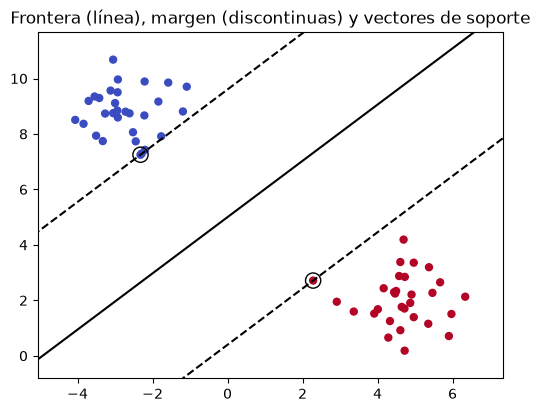

In [6]:
X2, y2 = make_blobs(n_samples=60, centers=2, cluster_std=0.9, random_state=42)
svm_lineal = SVC(kernel="linear", C=1000).fit(X2, y2)   # C grande: margen casi duro

w, b = svm_lineal.coef_[0], svm_lineal.intercept_[0]
print("Vectores de soporte:", len(svm_lineal.support_vectors_))
print("Ancho del margen 2/||w||:", round(2 / np.linalg.norm(w), 3))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="coolwarm", s=25)
xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - 1, X2[:, 0].max() + 1, 200),
                     np.linspace(X2[:, 1].min() - 1, X2[:, 1].max() + 1, 200))
zz = svm_lineal.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
ax.scatter(*svm_lineal.support_vectors_.T, s=120, facecolors="none", edgecolors="k")
ax.set_title("Frontera (línea), margen (discontinuas) y vectores de soporte")
plt.show()

## 6. Margen suave y el parámetro C

Con datos reales las clases se traslapan y ningún hiperplano las separa del todo. El **margen suave** permite violaciones $\xi_i \ge 0$ y las penaliza:

$$\min_{w,\,b,\,\xi}\ \tfrac12\lVert w\rVert^2 + C\sum_i \xi_i \quad \text{sujeto a} \quad y_i\,(w^\top x_i + b) \ge 1 - \xi_i,\ \ \xi_i \ge 0.$$

| C | Efecto |
| --- | --- |
| Pequeño | Tolera más errores: margen ancho, muchos vectores de soporte, modelo más simple |
| Grande | Castiga cada error: margen estrecho, riesgo de sobreajuste |

In [7]:
X3, y3 = make_blobs(n_samples=200, centers=2, cluster_std=2.2, random_state=42)

for C in [0.01, 1, 100]:
    m = SVC(kernel="linear", C=C).fit(X3, y3)
    ancho = 2 / np.linalg.norm(m.coef_[0])
    print(f"C={C:>6}: vectores de soporte={len(m.support_):3d}, ancho del margen={ancho:.2f}")

C=  0.01: vectores de soporte= 25, ancho del margen=5.18
C=     1: vectores de soporte=  4, ancho del margen=1.96
C=   100: vectores de soporte=  3, ancho del margen=0.85


## 7. El truco del kernel

La solución de la SVM se escribe solo con productos punto entre registros. La función de decisión es

$$f(x) = \sum_{i \in SV} \alpha_i\, y_i\, K(x_i, x) + b,$$

donde la suma recorre los vectores de soporte. Si se cambia el producto punto por una función **kernel** $K$, la SVM separa los datos en un espacio de mayor dimensión sin construirlo nunca. `SVC` ofrece cuatro kernels:

| `kernel` | $K(x, x')$ | Parámetros |
| --- | --- | --- |
| `"linear"` | $x^\top x'$ | `C` |
| `"poly"` | $(\gamma\, x^\top x' + r)^d$ | `degree` $=d$, `coef0` $=r$ |
| `"rbf"` | $\exp(-\gamma \lVert x - x'\rVert^2)$ | `gamma` |
| `"sigmoid"` | $\tanh(\gamma\, x^\top x' + r)$ | `coef0` $=r$ |

Por defecto `gamma="scale"`, es decir, $\gamma = 1/(p \cdot \operatorname{Var}(X))$, con $p$ el número de columnas. El kernel sigmoide no siempre da una matriz válida (semidefinida positiva), por lo que suele rendir peor.

In [8]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
modelos, filas = {}, []

for k in kernels:
    modelos[k] = make_pipeline(StandardScaler(), SVC(kernel=k)).fit(X_train, y_train)
    pred = modelos[k].predict(X_test)
    filas.append({"kernel": k,
                  "exactitud": accuracy_score(y_test, pred),
                  "precisión_1": precision_score(y_test, pred),
                  "recall_1": recall_score(y_test, pred),
                  "F1_1": f1_score(y_test, pred)})

resultados = pd.DataFrame(filas).set_index("kernel").round(3)
resultados

,exactitud,precisión_1,recall_1,F1_1
kernel,,,,
linear,0.764,0.509,0.235,0.322
poly,0.908,0.901,0.689,0.781
rbf,0.930,0.856,0.849,0.852
sigmoid,0.682,0.206,0.118,0.150


## 8. Matriz de confusión y métricas

La **matriz de confusión** cruza la clase real (filas) con la predicha (columnas). Tomando la clase 1 como positiva:

$$\text{precisión} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{TP + FN}, \qquad F_1 = 2\,\frac{\text{precisión}\cdot\text{recall}}{\text{precisión} + \text{recall}}.$$

La precisión responde "de los que marqué como positivos, ¿cuántos lo eran?"; el recall, "de los positivos reales, ¿cuántos encontré?". $F_1$ es su media armónica.

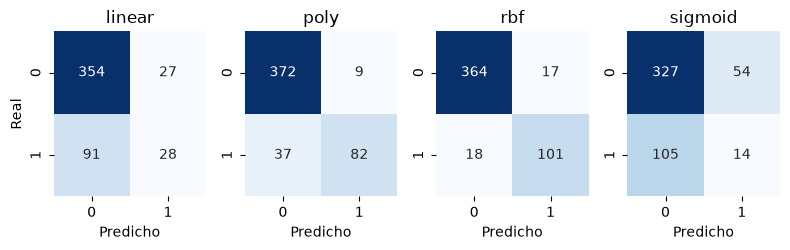

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(8, 2.6))
for ax, k in zip(axes, kernels):
    cm = confusion_matrix(y_test, modelos[k].predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax)
    ax.set_title(k)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real" if k == "linear" else "")
plt.tight_layout()
plt.show()

In [10]:
print(classification_report(y_test, modelos["rbf"].predict(X_test), digits=3))

              precision    recall  f1-score   support

           0      0.953     0.955     0.954       381
           1      0.856     0.849     0.852       119

    accuracy                          0.930       500
   macro avg      0.904     0.902     0.903       500
weighted avg      0.930     0.930     0.930       500



En el reporte, `support` es el número de casos reales de cada clase en la prueba, `macro avg` promedia las clases por igual y `weighted avg` las pondera por su tamaño.

## 9. Elegir la métrica adecuada

La exactitud no basta con clases desbalanceadas. La métrica se elige según el costo de cada error:

- Si dejar escapar a un empleado que se va (falso negativo) cuesta más que una alerta innecesaria (falso positivo), interesa el **recall de la clase 1**.
- Si cada alerta dispara una intervención cara, pesa más la **precisión**.
- $F_1$ equilibra ambas cuando no hay una preferencia clara.

In [11]:
mejor = resultados["recall_1"].idxmax()
print("Kernel con mayor recall de la clase 1:", mejor)
print(resultados.sort_values("recall_1", ascending=False)[["recall_1", "precisión_1", "F1_1"]])

Kernel con mayor recall de la clase 1: rbf
         recall_1  precisión_1   F1_1
kernel                               
rbf         0.849        0.856  0.852
poly        0.689        0.901  0.781
linear      0.235        0.509  0.322
sigmoid     0.118        0.206  0.150


En esta submuestra el kernel RBF obtiene el mayor recall y también el mejor $F_1$; el lineal queda muy por detrás porque la relación entre las variables y la salida no es lineal, y el sigmoide es el más débil.

## 10. Predecir un registro nuevo

Un registro nuevo debe pasar por **la misma codificación** que los datos de entrenamiento y terminar con **las mismas columnas en el mismo orden**. `reindex(columns=X.columns, fill_value=0)` agrega las dummies que falten con 0 y ordena las columnas.

In [12]:
nuevo = pd.DataFrame([{
    "satisfaction_level": 0.15, "last_evaluation": 0.85, "number_project": 6,
    "average_montly_hours": 270, "time_spend_company": 4, "Work_accident": 0,
    "promotion_last_5years": 0, "sales": "technical", "salary": "low",
}])

nuevo["salary"] = nuevo["salary"].map(orden_salario)
nuevo = pd.get_dummies(nuevo, columns=["sales"], dtype=int)
nuevo = nuevo.reindex(columns=X.columns, fill_value=0)

print("Columnas iguales:", list(nuevo.columns) == list(X.columns))
print("Predicción (1 = se va):", modelos["rbf"].predict(nuevo)[0])

Columnas iguales: True
Predicción (1 = se va): 1


## 11. Errores frecuentes

**Codificar el registro nuevo por separado.** `get_dummies` solo crea columnas para las categorías presentes. Con un único registro aparece una sola dummy, y el modelo recibiría otro número de columnas:

In [13]:
solo = pd.get_dummies(pd.DataFrame({"sales": ["technical"]}), columns=["sales"], dtype=int)
print("Columnas del registro aislado:", solo.columns.tolist())
print("Columnas de departamento en el entrenamiento:", sum(c.startswith("sales_") for c in X.columns))
# Forma correcta: reindex(columns=X.columns, fill_value=0), como en la sección 10

Columnas del registro aislado: ['sales_technical']
Columnas de departamento en el entrenamiento: 9


**Juzgar el modelo por la exactitud con clases desbalanceadas.** Un clasificador que siempre predice la clase mayoritaria ya alcanza una exactitud alta con recall 0:

In [14]:
siempre_cero = np.zeros(len(y_test), dtype=int)
print("Exactitud de 'nadie se va':", round(accuracy_score(y_test, siempre_cero), 3))
print("Recall de la clase 1:      ", recall_score(y_test, siempre_cero))

Exactitud de 'nadie se va': 0.762
Recall de la clase 1:       0.0


**Escalar con todos los datos antes de dividir.** Si `StandardScaler` se ajusta con el conjunto completo, la media y la desviación incluyen información de la prueba. Con `make_pipeline(StandardScaler(), SVC())` el ajuste del escalador ocurre solo dentro de `fit`, con los datos de entrenamiento.

**Olvidar escalar.** Como se vio en la sección 4, la SVM sin escalar queda dominada por la variable de mayor rango.

## 12. Ejercicio

Un gimnasio quiere anticipar qué socios cancelarán su membresía. Se simulan 1.200 socios con este código:

```python
rng = np.random.default_rng(42)
n = 1200
socios = pd.DataFrame({
    "edad": rng.integers(18, 70, n),
    "visitas_mes": rng.poisson(8, n),
    "meses_antiguedad": rng.integers(1, 60, n),
    "plan": rng.choice(["basico", "estandar", "premium"], n, p=[0.5, 0.35, 0.15]),
    "sede": rng.choice(["norte", "sur", "centro"], n),
})
```

La cancelación depende de forma no lineal de las visitas: cancelan más quienes casi no van y quienes van muchísimo, y menos quienes llevan años inscritos (ver la regla en la solución).

1. Codifica `plan` como ordinal y `sede` con `get_dummies(drop_first=True)`.
2. Divide en entrenamiento y prueba (25 %) de forma estratificada.
3. Entrena SVM con kernel lineal y RBF dentro de un pipeline con `StandardScaler`.
4. Compara el recall y el $F_1$ de la clase 1 y elige un kernel.
5. Predice si cancelará un socio de 30 años, 2 visitas al mes, 3 meses de antigüedad, plan básico y sede sur.

### Solución

In [15]:
rng = np.random.default_rng(42)
n = 1200
socios = pd.DataFrame({
    "edad": rng.integers(18, 70, n),
    "visitas_mes": rng.poisson(8, n),
    "meses_antiguedad": rng.integers(1, 60, n),
    "plan": rng.choice(["basico", "estandar", "premium"], n, p=[0.5, 0.35, 0.15]),
    "sede": rng.choice(["norte", "sur", "centro"], n),
})
# Regla no lineal: el riesgo crece al alejarse de 8 visitas al mes y baja con la antigüedad
riesgo = -0.5 + 0.15 * (socios["visitas_mes"] - 8) ** 2 - 0.05 * socios["meses_antiguedad"]
socios["cancela"] = (riesgo + rng.normal(0, 0.6, n) > 0).astype(int)
print("Proporción que cancela:", round(socios["cancela"].mean(), 3))

# 1. Codificación
planes = {"basico": 0, "estandar": 1, "premium": 2}
Xs = socios.drop(columns="cancela")
Xs["plan"] = Xs["plan"].map(planes)
Xs = pd.get_dummies(Xs, columns=["sede"], drop_first=True, dtype=int)
ys = socios["cancela"]

# 2. División estratificada
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.25, stratify=ys, random_state=42)

# 3 y 4. Kernels lineal y RBF
modelos_gym = {}
for k in ["linear", "rbf"]:
    modelos_gym[k] = make_pipeline(StandardScaler(), SVC(kernel=k)).fit(Xs_tr, ys_tr)
    p = modelos_gym[k].predict(Xs_te)
    print(f"{k:>6}: recall_1={recall_score(ys_te, p):.3f}, F1_1={f1_score(ys_te, p):.3f}")

Proporción que cancela: 0.26
linear: recall_1=0.000, F1_1=0.000
   rbf: recall_1=0.782, F1_1=0.841


In [16]:
# 5. Socio nuevo, con las mismas columnas que el entrenamiento
socio = pd.DataFrame([{"edad": 30, "visitas_mes": 2, "meses_antiguedad": 3,
                       "plan": "basico", "sede": "sur"}])
socio["plan"] = socio["plan"].map(planes)
socio = pd.get_dummies(socio, columns=["sede"], dtype=int).reindex(columns=Xs.columns, fill_value=0)
print("¿Cancela? (1 = sí):", modelos_gym["rbf"].predict(socio)[0])

¿Cancela? (1 = sí): 1


El kernel lineal no encuentra ningún caso positivo: una recta no puede separar una clase que aparece en los dos extremos de las visitas. El RBF capta esa forma de U, así que es el que se elige y el que se usa para el socio nuevo.

## Resumen

- Las variables nominales se codifican con `get_dummies(drop_first=True)`; las ordinales pueden mapearse a enteros que respeten su orden.
- Con clases desbalanceadas se submuestrea y se divide con `stratify`, y la exactitud deja de ser una buena guía.
- La SVM maximiza el margen $2/\lVert w\rVert$; el parámetro C regula cuántas violaciones del margen se toleran.
- El truco del kernel (lineal, polinomial, RBF, sigmoide) permite fronteras no lineales; siempre conviene escalar dentro de un `Pipeline`.
- La matriz de confusión, la precisión, el recall y $F_1$ permiten elegir el modelo según el costo de cada tipo de error.
- Un registro nuevo debe tener exactamente las mismas columnas que el entrenamiento.

En el **Módulo 25** se estudian los métodos de ensamble, que combinan muchos modelos sencillos en uno más robusto.